# 01 Data Overview

This notebook produces the results described in Sections 2 and 3, including Table 1 of the paper.

It uses two input data files:

* `TTau-2011-15A+O.csv` – calibrator-scaled light curve analysed throughout (identical to the `Sscaled` column in `TTAU-with-cal.csv`)
* `TTAU-with-cal.csv` – raw target flux (`Sraw`), scaled target flux (`Sscaled`) and the phase calibrator (`Scal`)

Flux densities in the files are in Jy.

In [1]:
import pandas as pd
import numpy as np
import pylab as pl

In [2]:
d = pd.read_csv('TTAU-with-cal.csv')
d2 = pd.read_csv('TTau-2011-15A+O.csv')

# check that data in files matches:
print("TTau-2011-15A+O.csv identical to Sscaled:", np.allclose(np.sort(d2.flux), np.sort(d.Sscaled)))

# MJD range:
mjd0, mjd1 = d.MJD.min(), d.MJD.max()

# MJD conversion to human readable dates:
to_date = lambda m: pd.to_datetime(m - 40587, unit="D").strftime("%Y %b %d")

# find gaps in monitoring:
gaps = np.diff(d2.MJD)

# print useful info:
print(f"N epochs        : {len(d2.MJD)}")
print(f"Span            : MJD {mjd0:.1f} ({to_date(mjd0)}) - {mjd1:.1f} ({to_date(mjd1)}), baseline {mjd1 - mjd0:.0f} d")
print(f"Median cadence  : {np.median(gaps):.2f} d; longest gap {gaps.max():.0f} d starting MJD {d2.MJD[np.argmax(gaps)]:.0f}")

TTau-2011-15A+O.csv identical to Sscaled: True
N epochs        : 357
Span            : MJD 55775.4 (2011 Aug 02) - 57222.4 (2015 Jul 19), baseline 1447 d
Median cadence  : 3.05 d; longest gap 58 d starting MJD 55792


## Data statistics

In [3]:
rows = []
for c in ["Sraw", "Sscaled", "Scal"]:
    s, e = d[c], d["d" + c]
    mad = 1.4826 * np.median(np.abs(s - s.median()))
    rows.append(dict(column=c, median_mJy=1e3 * s.median(), rms_frac=s.std() / s.mean(),
                     robust_sigma_mJy=1e3 * mad, robust_frac=mad / s.median(),
                     median_err_mJy=1e3 * e.median(), median_SN=np.median(s / e)))
pd.DataFrame(rows).round(3)

,column,median_mJy,rms_frac,robust_sigma_mJy,robust_frac,median_err_mJy,median_SN
0,Sraw,9.122,0.180,1.185,0.130,0.172,54.040
1,Sscaled,9.171,0.170,1.182,0.129,0.170,54.067
2,Scal,128.803,0.073,9.960,0.077,1.144,112.450


---
## Find flares

Points more than 4 robust standard deviations ($\sigma_{\rm rob} = 1.4826\times$MAD) from the median are removed iteratively.

In [4]:
def clip_bursts(t, y, dy, nsig):
    """
    Iteratively remove points > nsig robust sigmas from the median
    (e.g. accretion bursts / flares that dominate a periodogram).
    """
    
    keep = np.ones_like(y, bool)
    for _ in range(5):
        med = np.median(y[keep])
        mad = 1.4826 * np.median(np.abs(y[keep] - med))
        new = np.abs(y - med) < nsig * mad
        if (new == keep).all():
            break
        keep = new
    return t[keep], y[keep], dy[keep], (~keep).sum()

In [5]:
CLIP = 4.0 # number of standard deviations

tc, yc, dyc, nclip = clip_bursts(d2.MJD, d2.flux, d2.error, CLIP)

burst = ~np.isin(d2.MJD, tc)
med = np.median(d2.flux)
sig = 1.4826 * np.median(np.abs(d2.flux - med))

print(f"Clipped {nclip} of {len(d2.MJD)} points; median = {1e3*med:.2f} mJy, sigma_rob = {1e3*sig:.2f} mJy")
pd.DataFrame({"MJD": d2.MJD[burst], "S16_mJy": 1e3 * d2.flux[burst], "S/S_med": d2.flux[burst] / med,
              "(S-S_med)/sigma_rob": (d2.flux[burst] - med) / sig}).round(2)

Clipped 7 of 357 points; median = 9.17 mJy, sigma_rob = 1.18 mJy


,MJD,S16_mJy,S/S_med,(S-S_med)/sigma_rob
6,55871.12,16.18,1.76,5.93
9,55893.06,16.23,1.77,5.97
154,56489.34,14.31,1.56,4.35
160,56507.25,20.39,2.22,9.50
172,56552.09,15.28,1.67,5.17
224,56747.78,17.22,1.88,6.81
299,56996.99,16.01,1.75,5.79


---
## Make light curve

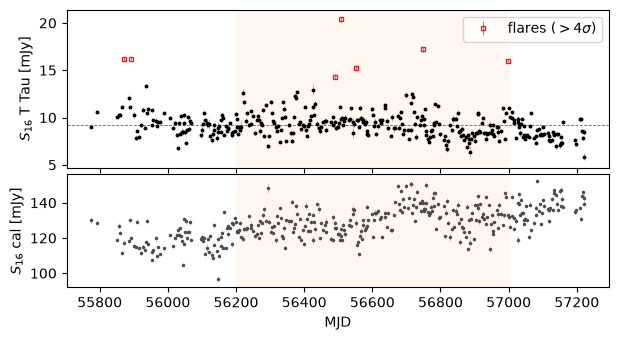

In [6]:
t = d2.MJD; y = d2.flux; dy = d2.error
COL_W, PAGE_W = 3.4, 7.0

fig, ax = pl.subplots(2, 1, figsize=(PAGE_W, 3.6), sharex=True,
                       gridspec_kw=dict(hspace=0.05, height_ratios=[1.4, 1]))

# plot target data points:
ax[0].errorbar(t[~burst], 1e3 * y[~burst], 1e3 * dy[~burst], fmt="o", ms=1.8, color="k", ecolor="0.6", lw=0.5)

# highlight flares:
ax[0].errorbar(t[burst], 1e3 * y[burst], 1e3 * dy[burst], fmt="s", ms=3, mfc="none", color="C3", lw=0.5,
               label=r"flares ($>{}\sigma$)".format(int(CLIP)))

# add median flux line:
ax[0].axhline(1e3 * med, color="C0", lw=0.6, ls="--")

# labels and legend:
ax[0].set_ylabel("$S_{16}$ T Tau [mJy]")
ax[0].legend(loc="upper right", frameon=True)

# plot calibrator data points:
ax[1].errorbar(d.MJD, 1e3 * d.Scal, 1e3 * d.dScal, fmt="o", ms=1.5, color="0.3", ecolor="0.7", lw=0.5)
ax[1].set(ylabel="$S_{16}$ cal [mJy]", xlabel="MJD")

# shade segment used for drift tests:
for a in ax:
    a.axvspan(56200, 57000, color="C1", alpha=0.06, lw=0)   # segment used for the drift test
fig.savefig("lightcurve.pdf")

pl.show()